<a href="https://colab.research.google.com/github/samiyaalizaidi/music-similarity-representation-learning/blob/main/notebooks/02_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 — FMA preprocessing

This notebook **runs** `scripts/prepare_data.py`; it does not duplicate preprocessing. The script is the single source of truth. Requires extracted `features.csv` and `tracks.csv` in `data/fma_metadata/`.



## 1. Imports and project paths

### Ensure Repo is Cloned

In [2]:
from pathlib import Path

REPO_NAME = "music-similarity-representation-learning"
REPO_URL = "https://github.com/samiyaalizaidi/music-similarity-representation-learning.git"

if not Path(f"/content/{REPO_NAME}").exists():
    !git clone {REPO_URL}

%cd /content/music-similarity-representation-learning

Cloning into 'music-similarity-representation-learning'...
remote: Enumerating objects: 25, done.
remote: Counting objects: 100% (25/25), done.
remote: Compressing objects: 100% (17/17), done.
remote: Total 25 (delta 6), reused 20 (delta 4), pack-reused 0 (from 0)
Receiving objects: 100% (25/25), 10.37 KiB | 482.00 KiB/s, done.
Resolving deltas: 100% (6/6), done.
/content/music-similarity-representation-learning


In [3]:
from pathlib import Path

print("Current directory:", Path.cwd())

print("Preprocessing script exists:",
      Path("scripts/prepare_data.py").exists())

print("Baseline script exists:",
      Path("scripts/baseline.py").exists())

Current directory: /content/music-similarity-representation-learning
Preprocessing script exists: True
Baseline script exists: True


### Imports

In [4]:
from pathlib import Path
import sys
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [cwd, *cwd.parents] if (p / "scripts" / "prepare_data.py").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not find scripts/prepare_data.py. Open notebook inside the repository.")
DATA_DIR = PROJECT_ROOT / "data" / "fma_metadata"
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed"
print("Project:", PROJECT_ROOT)
print("Python:", sys.executable)


Project: /content/music-similarity-representation-learning
Python: /usr/bin/python3


### Download Dataset

In [6]:
from pathlib import Path
import urllib.request
import zipfile

DATA_DIR = PROJECT_ROOT / "data" / "fma_metadata"
DATA_DIR.mkdir(parents=True, exist_ok=True)

url = "https://os.unil.cloud.switch.ch/fma/fma_metadata.zip"
zip_path = PROJECT_ROOT / "data" / "fma_metadata.zip"

if not (DATA_DIR / "features.csv").exists():
    print("Downloading FMA metadata...")
    urllib.request.urlretrieve(url, zip_path)

    print("Extracting metadata...")
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(PROJECT_ROOT / "data")

    zip_path.unlink()
    print("Download and extraction complete!")

print("Features:", (DATA_DIR / "features.csv").exists())
print("Tracks:", (DATA_DIR / "tracks.csv").exists())

Extracting metadata...
Download and extraction complete!
Features: True
Tracks: True


## 2. Run the reusable preprocessing script

Uses FMA-small's predefined splits. Training data alone determines imputation, feature selection, and scaling.

In [7]:
command = [sys.executable, str(PROJECT_ROOT / "scripts" / "prepare_data.py"),
           "--data-dir", str(DATA_DIR), "--output-dir", str(OUTPUT_DIR)]
subprocess.run(command, check=True, cwd=PROJECT_ROOT)

CompletedProcess(args=['/usr/bin/python3', '/content/music-similarity-representation-learning/scripts/prepare_data.py', '--data-dir', '/content/music-similarity-representation-learning/data/fma_metadata', '--output-dir', '/content/music-similarity-representation-learning/data/processed'], returncode=0)

## 3. Inspect the generated artifacts

In [8]:
arrays = {}
for split in ("training", "validation", "test"):
    with np.load(OUTPUT_DIR / f"{split}.npz") as data:
        arrays[split] = {"X": data["X"], "track_ids": data["track_ids"]}
    X = arrays[split]["X"]
    print(f"{split:10} X={X.shape}, dtype={X.dtype}, finite={np.isfinite(X).all()}")

assert len({arrays[s]["X"].shape[1] for s in arrays}) == 1
assert all(np.isfinite(arrays[s]["X"]).all() for s in arrays)
assert all(len(arrays[s]["track_ids"]) == len(arrays[s]["X"]) for s in arrays)
assert not (set(arrays["training"]["track_ids"]) & set(arrays["test"]["track_ids"]))

training   X=(6400, 518), dtype=float32, finite=True
validation X=(800, 518), dtype=float32, finite=True
test       X=(800, 518), dtype=float32, finite=True


In [9]:
metadata = pd.read_csv(OUTPUT_DIR / "metadata.csv", index_col="track_id")
display(metadata.head())
print("Split counts:")
display(metadata["split"].value_counts())
print("Top genres:")
display(metadata["genre"].value_counts(dropna=False).head(12))

,split,genre,title,artist,tags
track_id,,,,,
2,training,Hip-Hop,Food,AWOL,[]
5,training,Hip-Hop,This World,AWOL,[]
10,training,Pop,Freeway,Kurt Vile,[]
140,training,Folk,Queen Of The Wires,Alec K. Redfearn & the Eyesores,[]
141,training,Folk,Ohio,Alec K. Redfearn & the Eyesores,[]


Split counts:


,count
split,
training,6400
validation,800
test,800


Top genres:


,count
genre,
Hip-Hop,1000
Pop,1000
Folk,1000
Experimental,1000
Rock,1000
International,1000
Electronic,1000
Instrumental,1000


## Quick Sanity Check Visualization

A histogram of the first standardized feature in the training set.

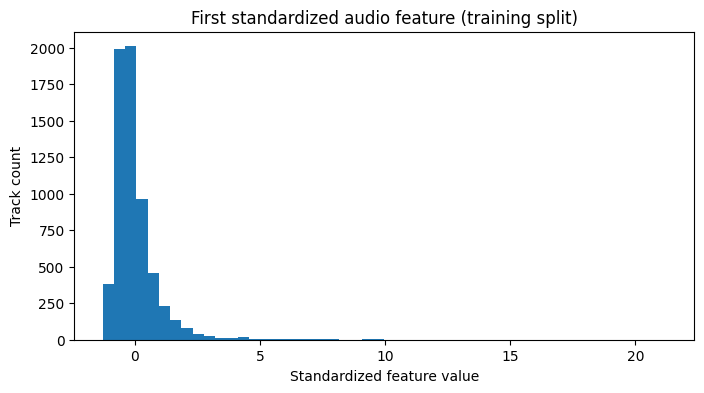

Average training-feature mean: -8.1580485e-09
Median training-feature std: 0.9999998


In [10]:
X_train = arrays["training"]["X"]
plt.figure(figsize=(8, 4))
plt.hist(X_train[:, 0], bins=50)
plt.title("First standardized audio feature (training split)")
plt.xlabel("Standardized feature value")
plt.ylabel("Track count")
plt.show()
print("Average training-feature mean:", np.mean(X_train.mean(axis=0)))
print("Median training-feature std:", np.median(X_train.std(axis=0)))

# Interface for the autoencoder

In [11]:
import torch
X_train_tensor = torch.from_numpy(arrays["training"]["X"])
X_val_tensor = torch.from_numpy(arrays["validation"]["X"])
input_dim = X_train_tensor.shape[1]
print("Autoencoder input dimension:", input_dim)
print("Train:", tuple(X_train_tensor.shape), "Validation:", tuple(X_val_tensor.shape))


Autoencoder input dimension: 518
Train: (6400, 518) Validation: (800, 518)
